# AI5707 — Assignment 8
## Pattern Recognition and Machine Learning

**Team 16**

This notebook implements the assignment experiment with handwritten algorithms. The shared module contains the LCG random generator, polar Box–Muller Gaussian generator, and from-scratch models. No scikit-learn model implementation is used.

## 1. Imports and common implementations

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd()
if not (ROOT / "assignment8_common.py").exists(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from assignment8_common import *
print("Dataset directory:", DATA)
print("Random generator seed:", seed)

Dataset directory: D:\Storage\OneDrive\Documents\SNU Chennai\PRML Lab\AI5707_Assignment8_Manual\DATASETS
Random generator seed: 42


## 2. Load the supplied MNIST-labelled dataset

In [2]:
import pickle
path = DATA / "team16_mnist" / "data.pkl"
with open(path,"rb") as f: data=pickle.load(f)
X=np.asarray(data["x"],dtype=float); y=np.asarray(data["y"]).ravel()
print("Features:",X.shape,"Labels:",y.shape,"Classes:",np.unique(y,return_counts=True))

Features: (20000, 16) Labels: (20000,) Classes: (array([0, 1], dtype=int64), array([10000, 10000], dtype=int64))


> **Dataset validation warning:** The supplied `team16_mnist/data.pkl` was checked against `team16_Synthetic/data.pkl` and appears to contain identical X and y arrays. Results below are strictly for the supplied MNIST-labelled pickle and must not be reported as verified MNIST results.

## 3. Train-test split

In [3]:
X_train,X_test,y_train,y_test=deterministic_split(X,y,0.20)
print("Train:",X_train.shape,"Test:",X_test.shape)

Train: (16000, 16) Test: (4000, 16)


## 4. GMM (EM implementation)

In [4]:
m,s=standardize_fit(X_train); A=standardize_transform(X_train,m,s); B=standardize_transform(X_test,m,s)
gmm_pred=gmm_predict(A,y_train,B,K=1)
print("GMM accuracy:",f"{accuracy_score(y_test,gmm_pred)*100:.2f}%")

GMM accuracy: 97.90%


## 5. LDA (from scratch)

In [5]:
lda=LDAFromScratch().fit(A,y_train); lda_pred=lda.predict(B)
print("LDA accuracy:",f"{accuracy_score(y_test,lda_pred)*100:.2f}%")

LDA accuracy: 96.65%


## 6. KNN (from scratch)

In [6]:
knn=KNNFromScratch(5).fit(A,y_train); knn_pred=knn.predict(B)
print("KNN accuracy:",f"{accuracy_score(y_test,knn_pred)*100:.2f}%")

KNN accuracy: 99.67%


## 7. SVM (SMO + RBF, one-vs-rest)

In [7]:
ix=deterministic_permutation(len(A))[:min(1200,len(A))]
svm=SVMFromScratch(C=2,max_passes=4,max_iter=300).fit(A[ix],y_train[ix]); svm_pred=svm.predict(B)
print("SVM accuracy:",f"{accuracy_score(y_test,svm_pred)*100:.2f}%")

SVM accuracy: 99.20%


## 8. PCA experiments

{'Features': 'Original', 'GMM': 0.979, 'LDA': 0.9665, 'KNN': 0.99675, 'SVM': 0.995}
{'Features': 'PCA-2', 'GMM': 0.9125, 'LDA': 0.90725, 'KNN': 0.9105, 'SVM': 0.91175}
{'Features': 'PCA-4', 'GMM': 0.93125, 'LDA': 0.92, 'KNN': 0.93025, 'SVM': 0.9335}
{'Features': 'PCA-8', 'GMM': 0.95975, 'LDA': 0.93675, 'KNN': 0.97225, 'SVM': 0.96575}
{'Features': 'PCA-12', 'GMM': 0.97825, 'LDA': 0.956, 'KNN': 0.99225, 'SVM': 0.99075}


,Features,GMM,LDA,KNN,SVM
0,Original,0.97900,0.96650,0.99675,0.99500
1,PCA-2,0.91250,0.90725,0.91050,0.91175
2,PCA-4,0.93125,0.92000,0.93025,0.93350
3,PCA-8,0.95975,0.93675,0.97225,0.96575
4,PCA-12,0.97825,0.95600,0.99225,0.99075


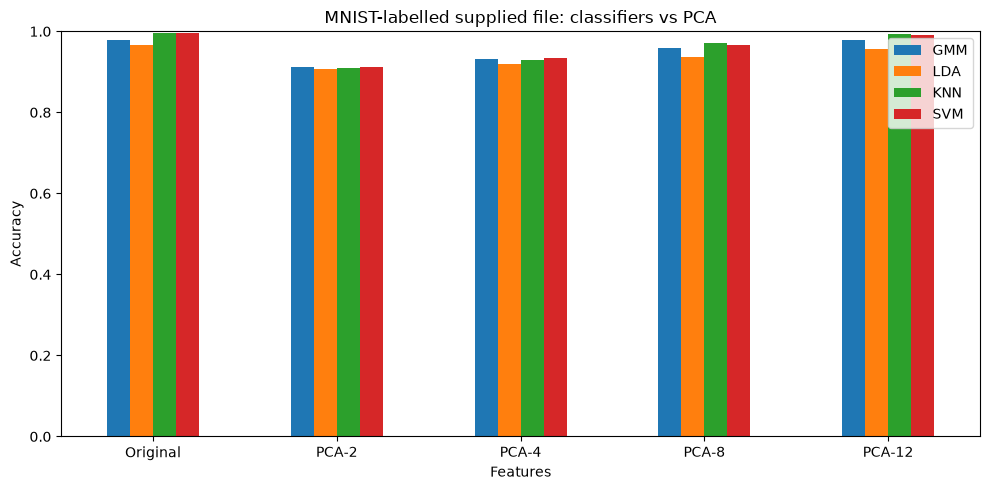

In [8]:
results=[]
for k in [None,2,4,8,12]:
    if k is not None and k>=A.shape[1]: continue
    scores=evaluate_classifiers(X_train,y_train,X_test,y_test,pca_k=k)
    results.append({"Features":"Original" if k is None else f"PCA-{k}",**scores})
    print(results[-1])
    
result_df=pd.DataFrame(results); display(result_df)
ax=result_df.set_index("Features")[["GMM","LDA","KNN","SVM"]].plot(kind="bar",ylim=(0,1),figsize=(10,5))

ax.set_ylabel("Accuracy"); ax.set_title("MNIST-labelled supplied file: classifiers vs PCA"); 
plt.xticks(rotation=0); plt.tight_layout(); plt.show()
result_df.to_csv(OUT/"mnist_labelled_file_results.csv",index=False)